In [19]:
import time

import torch 
from torch import nn, Tensor
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import make_grid
import numpy as np

import matplotlib.pyplot as plt
from sklearn.datasets import make_moons

In [3]:
device = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')

### Load MNIST dataset

In [4]:


# Normalize pixel values from [0, 1] to [-1, 1] so the data matches a standard
# Gaussian source for flow matching.
transform = transforms.Compose([
    transforms.ToTensor(),
])

train_dataset = datasets.MNIST(root='../data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='../data', train=False, download=True, transform=transform)

batch_size = 128
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f'Train samples: {len(train_dataset)}, Test samples: {len(test_dataset)}')
images, labels = next(iter(train_loader))
print(f'Batch images shape: {images.shape}, labels shape: {labels.shape}')

Train samples: 60000, Test samples: 10000
Batch images shape: torch.Size([128, 1, 28, 28]), labels shape: torch.Size([128])


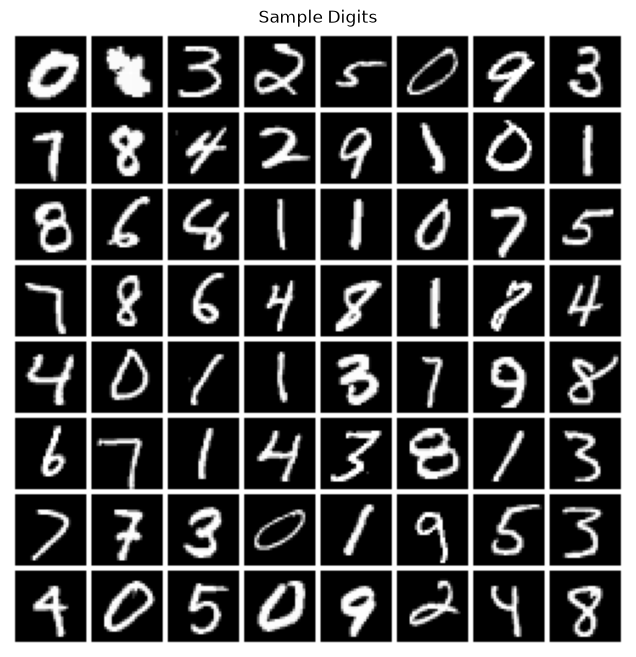

In [5]:
## Display some sample digits

def show_samples(images: Tensor, nrow: int=8, ax=None):
    # images = (images + 1) / 2  # denormalize
    images = images.clamp(0, 1)
    grid = make_grid(images[:nrow**2], nrow, padding=2, pad_value=1)
    if ax is None:
        _, ax = plt.subplots(figsize=(8, 8))
    ax.set_aspect('equal')
    ax.set_title('Sample Digits')
    ax.imshow(grid.permute(1, 2, 0).cpu())
    ax.axis('off')
    return ax

show_samples(images);

### Train unconditioned FM

In [9]:
class Flow(nn.Module):

    def __init__(self, dim: int=28*28, h: int=128):
        super().__init__()
        self.dim = dim
        self.h = h

        self.net = nn.Sequential(
            nn.Linear(dim+1, 2*h),
            nn.ReLU(),
            nn.Linear(2*h, h),
            nn.ReLU(),
            nn.Linear(h, 2*h),
            nn.ReLU(),
            nn.Linear(2*h, dim),
        )
    def forward(self, x, t):
        x_t = torch.cat([x, t], dim=1)
        return self.net(x_t)

    def step(self, x_t: Tensor, t_start: float, t_end: float):
        t_start = t_start.view(1, 1).expand(x_t.shape[0], 1)
        dt = t_end - t_start
        return x_t + dt * self(x_t + self(x_t, t=t_start)*dt/2, t=(t_start + t_end)/2)



In [8]:
N_EPOCHS = 50

flow = Flow(h=256).to(device)
opt = torch.optim.Adam(flow.parameters(), lr=1e-3)

for e in range(N_EPOCHS):
    for i, (x, _) in enumerate(train_loader):
        x_1 = x.view(-1, 784).to(device)

        t = torch.rand(x.shape[0], 1, device=x_1.device)
        x_0 = torch.randn_like(x_1)*0.2 + 0.5
        dx_t = x_1 - x_0
        x_t = (1-t)*x_0 + t * x_1
        flow_pred = flow(x_t, t)

        loss = (flow_pred - dx_t).pow(2).sum(dim=1).mean()
        loss.backward()
        opt.step()
        opt.zero_grad()

        if i % 50 == 0:
            print(f'Epoch: {e}, Iter: {i}, Loss: {loss.item():.4f}')


Epoch: 0, Iter: 0, Loss: 214.4180
Epoch: 0, Iter: 50, Loss: 85.0983
Epoch: 0, Iter: 100, Loss: 77.4759
Epoch: 0, Iter: 150, Loss: 70.2414
Epoch: 0, Iter: 200, Loss: 64.7878
Epoch: 0, Iter: 250, Loss: 66.4900
Epoch: 0, Iter: 300, Loss: 61.3462
Epoch: 0, Iter: 350, Loss: 60.5459
Epoch: 0, Iter: 400, Loss: 60.6357
Epoch: 0, Iter: 450, Loss: 58.7300
Epoch: 1, Iter: 0, Loss: 57.0106
Epoch: 1, Iter: 50, Loss: 57.6221
Epoch: 1, Iter: 100, Loss: 56.0544
Epoch: 1, Iter: 150, Loss: 61.1894
Epoch: 1, Iter: 200, Loss: 56.0283
Epoch: 1, Iter: 250, Loss: 56.0707
Epoch: 1, Iter: 300, Loss: 56.2016
Epoch: 1, Iter: 350, Loss: 55.6679
Epoch: 1, Iter: 400, Loss: 57.3116
Epoch: 1, Iter: 450, Loss: 56.6449
Epoch: 2, Iter: 0, Loss: 55.7460
Epoch: 2, Iter: 50, Loss: 54.2183
Epoch: 2, Iter: 100, Loss: 55.5858
Epoch: 2, Iter: 150, Loss: 56.1752
Epoch: 2, Iter: 200, Loss: 56.7113
Epoch: 2, Iter: 250, Loss: 55.0766
Epoch: 2, Iter: 300, Loss: 52.6586
Epoch: 2, Iter: 350, Loss: 53.7033
Epoch: 2, Iter: 400, Loss: 5

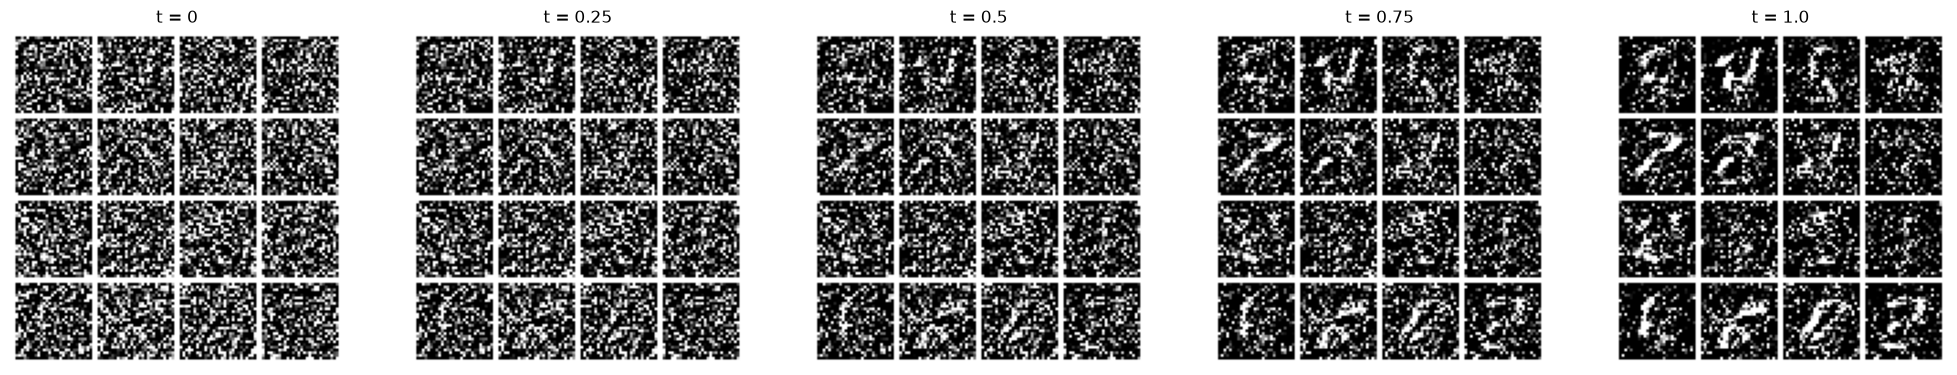

In [9]:
x = torch.randn(16, 784).to(device)
n_steps = 100
time_steps = torch.linspace(0, 1.0, n_steps + 1)

# Precompute the point cloud at every time step.
states = [x]
with torch.no_grad():
    for i in range(n_steps):
        x = flow.step(x_t=x, t_start=time_steps[i].to(device), t_end=time_steps[i + 1].to(device))
        states.append(x)
states = [s.detach() for s in states]

fig, ax = plt.subplots(1, 5, figsize=(25, 10))
ax = ax.reshape(-1)
ax[0] = show_samples(states[0].view(-1, 1, 28, 28), nrow=4, ax=ax[0])
ax[0].set_title('t = 0')
ax[1] = show_samples(states[25].view(-1, 1, 28, 28), nrow=4, ax=ax[1])
ax[1].set_title('t = 0.25')
ax[2] = show_samples(states[50].view(-1, 1, 28, 28), nrow=4, ax=ax[2])
ax[2].set_title('t = 0.5')
ax[3] = show_samples(states[75].view(-1, 1, 28, 28), nrow=4, ax=ax[3])
ax[3].set_title('t = 0.75')
ax[4] = show_samples(states[-1].view(-1, 1, 28, 28), nrow=4, ax=ax[4])
ax[4].set_title('t = 1.0')

plt.show()


### Effect of noise variance

In [ ]:
def train_flow(flow, train_loader, n_epochs=50, lr=1e-3, sigma_noise=0.2, device=device):
    losses = []
    opt = torch.optim.Adam(flow.parameters(), lr=lr)
    for e in range(n_epochs):
        current_loss = 0.0
        for i, (x, _) in enumerate(train_loader):
            x_1 = x.view(-1, 784).to(device)

            t = torch.rand(x.shape[0], 1, device=x_1.device)
            x_0 = torch.randn_like(x_1)*sigma_noise + 0.5
            dx_t = x_1 - x_0
            x_t = (1-t)*x_0 + t * x_1
            flow_pred = flow(x_t, t)

            loss = (flow_pred - dx_t).pow(2).sum(dim=1).mean()
            loss.backward()
            opt.step()
            opt.zero_grad()

            current_loss += loss.item()
        avg_loss = current_loss / len(train_loader)
        losses.append(avg_loss)

    return losses

Training completed for sigma=0.1. Final loss: 19.5449
Training completed for sigma=0.2. Final loss: 47.6201
Training completed for sigma=0.5. Final loss: 204.8077
Training completed for sigma=1.0. Final loss: 726.5159


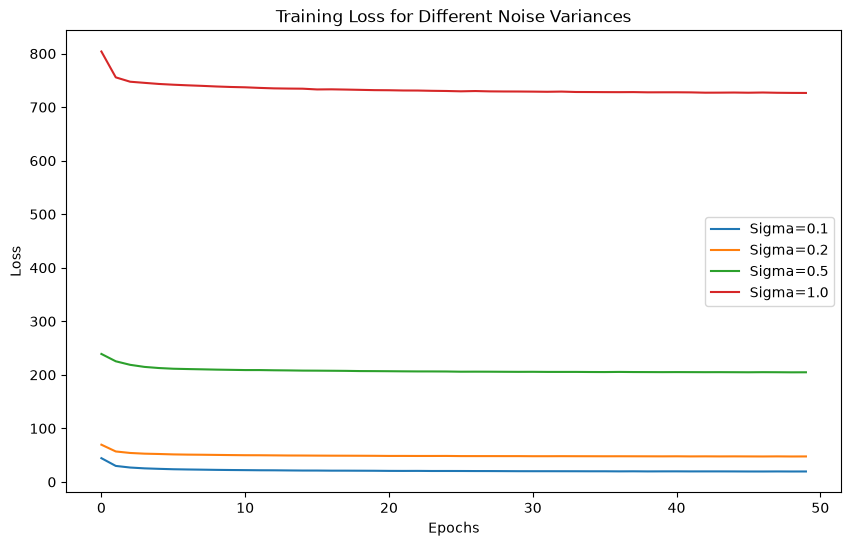

In [ ]:
SIGMAS = [0.1, 0.2, 0.5, 1.0]
sigma_losses = {}
sigma_flows = {}
for sigma in SIGMAS:
    flow = Flow(h=256).to(device)
    losses = train_flow(flow, train_loader, n_epochs=50, lr=1e-3, sigma_noise=sigma, device=device)
    sigma_losses[sigma] = losses
    sigma_flows[sigma] = flow
    print(f'Training completed for sigma={sigma}. Final loss: {losses[-1]:.4f}')



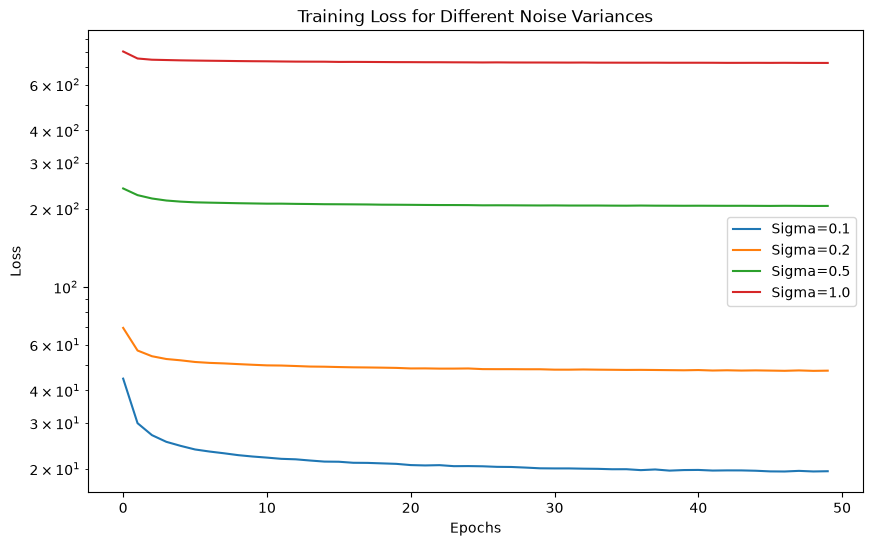

In [33]:
fig, ax = plt.subplots(figsize=(10, 6))
for sigma, losses in sigma_losses.items():
    ax.plot(losses, label=f'Sigma={sigma}')
ax.set_yscale('log')
ax.set_title('Training Loss for Different Noise Variances')
ax.set_xlabel('Epochs')
ax.set_ylabel('Loss')
ax.legend()
plt.show()

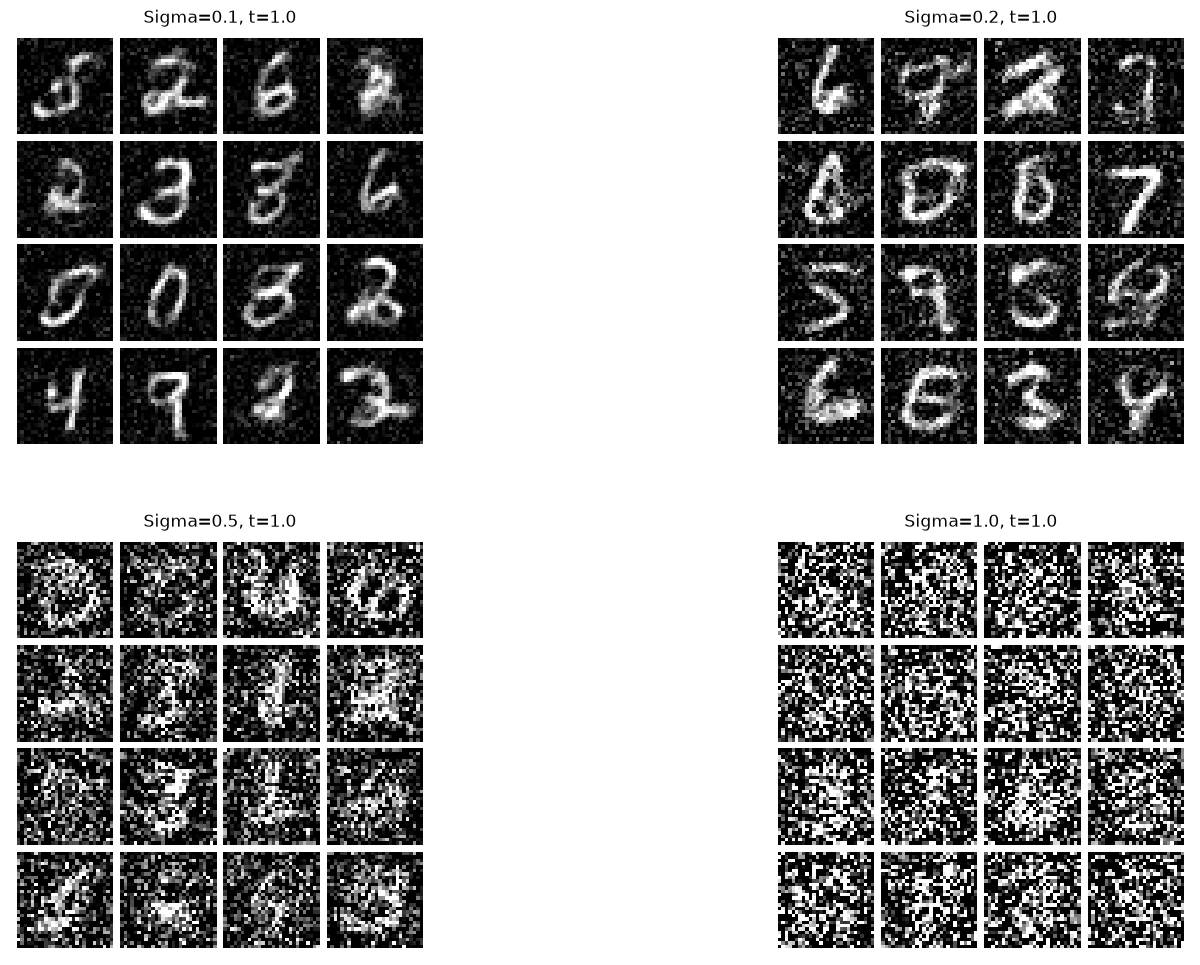

In [30]:
fig, ax = plt.subplots(2, 2, figsize=(18, 12))
ax = ax.reshape(-1)
for j, (sigma, model) in enumerate(sigma_flows.items()):
    x = torch.randn(16, 784).to(device)*sigma + 0.5
    n_steps = 100
    time_steps = torch.linspace(0, 1.0, n_steps + 1)

    with torch.no_grad():
        for i in range(n_steps):
            x = model.step(x_t=x, t_start=time_steps[i].to(device), t_end=time_steps[i + 1].to(device))

    show_samples(x.detach().view(-1, 1, 28, 28), nrow=4, ax=ax[j])
    ax[j].set_title(f'Sigma={sigma}, t=1.0')

plt.show()

### Learning conditional embeddings

In [ ]:
class CondFlow(nn.Module):
    def __init__(self, dim: int = 784, h: int = 64, c_dim: int = 2):
        super().__init__()
        self.class_emb = nn.Embedding(10, c_dim)
        self.encoder = nn.Sequential(
            nn.Linear(dim+c_dim+1, h),
            nn.ReLU(),
            nn.Linear(h, h),
        )
        self.decoder = nn.Sequential(
            nn.Linear(h, h),
            nn.ReLU(),
            nn.Linear(h, dim),
            # nn.Sigmoid()
        )
    
    def forward(self, t: Tensor, c: Tensor, x_t: Tensor ) -> Tensor:
        c_emb = self.class_emb(c)
        inp = torch.cat((x_t, c_emb, t), 1)
        z = self.encoder(inp)
        return self.decoder(z)
    
    def step(self, x_t: Tensor, t_start: Tensor, t_end: Tensor, c: Tensor) -> Tensor:
        t_start = t_start.view(1, 1).expand(x_t.shape[0], 1)
        dt = t_end - t_start
        return x_t + dt * self(x_t=x_t + self(x_t=x_t, t=t_start, c=c)*dt/2, t=t_start + dt/2, c=c)
        # return x_t + dt * self(x_t=x_t + self(x_t=x_t, t=t_start, c=c)*dt/2, t=(t_start + t_end)/2, c=c)
        
        # return x_t + (t_end - t_start) * self(t=t_start + (t_end - t_start) / 2, c=c, x_t= x_t + self(c=c, x_t=x_t, t=t_start) * (t_end - t_start) / 2)

In [35]:
def train_cond(flow, train_loader, n_epochs=50, lr=1e-3, sigma_noise=0.1, device=device):
    losses = []
    opt = torch.optim.Adam(flow.parameters(), lr=lr)
    for e in range(n_epochs):
        current_loss = 0.0
        for i, (x, c) in enumerate(train_loader):
            x_1 = x.view(-1, 784).to(device)
            c = c.to(device)

            t = torch.rand(x.shape[0], 1, device=x_1.device)
            x_0 = torch.randn_like(x_1)*sigma_noise + 0.5
            dx_t = x_1 - x_0
            x_t = (1-t)*x_0 + t * x_1
            flow_pred = flow(t=t, c=c, x_t=x_t)

            loss = (flow_pred - dx_t).pow(2).sum(dim=1).mean()
            loss.backward()
            opt.step()
            opt.zero_grad()

            current_loss += loss.item()
        avg_loss = current_loss / len(train_loader)
        losses.append(avg_loss)

    return losses

In [9]:
N_EPOCHS = 100

cond_flow = CondFlow(h=512).to(device)
opt = torch.optim.Adam(cond_flow.parameters(), lr=1e-3)
losses = []
preds = []
for e in range(N_EPOCHS):
    tot_loss = 0
    n = 0
    for i, (x, l) in enumerate(train_loader):
        x_1 = x.view(-1, 784).to(device)
        l = l.to(device)

        t = torch.rand(x.shape[0], 1, device=x_1.device)
        x_0 = torch.randn_like(x_1)*0.2 + 0.5
        dx_t = x_1 - x_0
        x_t = (1-t)*x_0 + t * x_1
        flow_pred = cond_flow(x_t=x_t, t=t, c=l)

        loss = (flow_pred - dx_t).pow(2).sum(dim=1).mean()
        loss.backward()
        tot_loss += loss.item()
        n+=1
        opt.step()
        opt.zero_grad()

        if i % 200 == 0:
            print(f'Epoch: {e}, Iter: {i}, Loss: {loss.item():.4f}')
    preds.append(flow_pred[0].cpu().detach().numpy())
    losses.append(tot_loss/n)

Epoch: 0, Iter: 0, Loss: 213.4617
Epoch: 0, Iter: 200, Loss: 65.5785
Epoch: 0, Iter: 400, Loss: 59.2624
Epoch: 1, Iter: 0, Loss: 57.8988
Epoch: 1, Iter: 200, Loss: 53.4376
Epoch: 1, Iter: 400, Loss: 53.6751
Epoch: 2, Iter: 0, Loss: 53.2285
Epoch: 2, Iter: 200, Loss: 51.8720
Epoch: 2, Iter: 400, Loss: 50.4598
Epoch: 3, Iter: 0, Loss: 49.4674
Epoch: 3, Iter: 200, Loss: 52.5484
Epoch: 3, Iter: 400, Loss: 50.9218
Epoch: 4, Iter: 0, Loss: 49.5104
Epoch: 4, Iter: 200, Loss: 49.5882
Epoch: 4, Iter: 400, Loss: 48.9818
Epoch: 5, Iter: 0, Loss: 48.2329
Epoch: 5, Iter: 200, Loss: 49.5853
Epoch: 5, Iter: 400, Loss: 49.0465
Epoch: 6, Iter: 0, Loss: 50.2110
Epoch: 6, Iter: 200, Loss: 48.5714
Epoch: 6, Iter: 400, Loss: 49.5155
Epoch: 7, Iter: 0, Loss: 47.3378
Epoch: 7, Iter: 200, Loss: 49.6651
Epoch: 7, Iter: 400, Loss: 47.7826
Epoch: 8, Iter: 0, Loss: 49.4981
Epoch: 8, Iter: 200, Loss: 47.3985
Epoch: 8, Iter: 400, Loss: 48.2167
Epoch: 9, Iter: 0, Loss: 47.3736
Epoch: 9, Iter: 200, Loss: 48.8963
Epoc

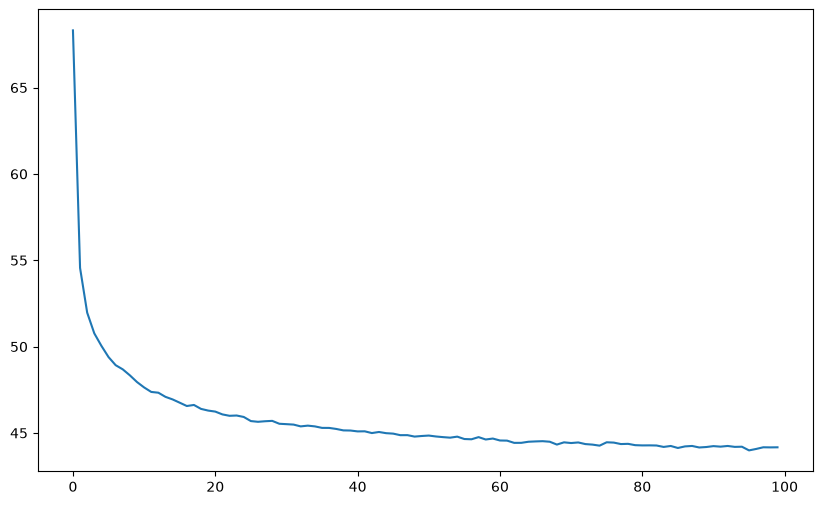

In [10]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(losses)
plt.show();

In [11]:
preds = [torch.Tensor(pred) for pred in preds]

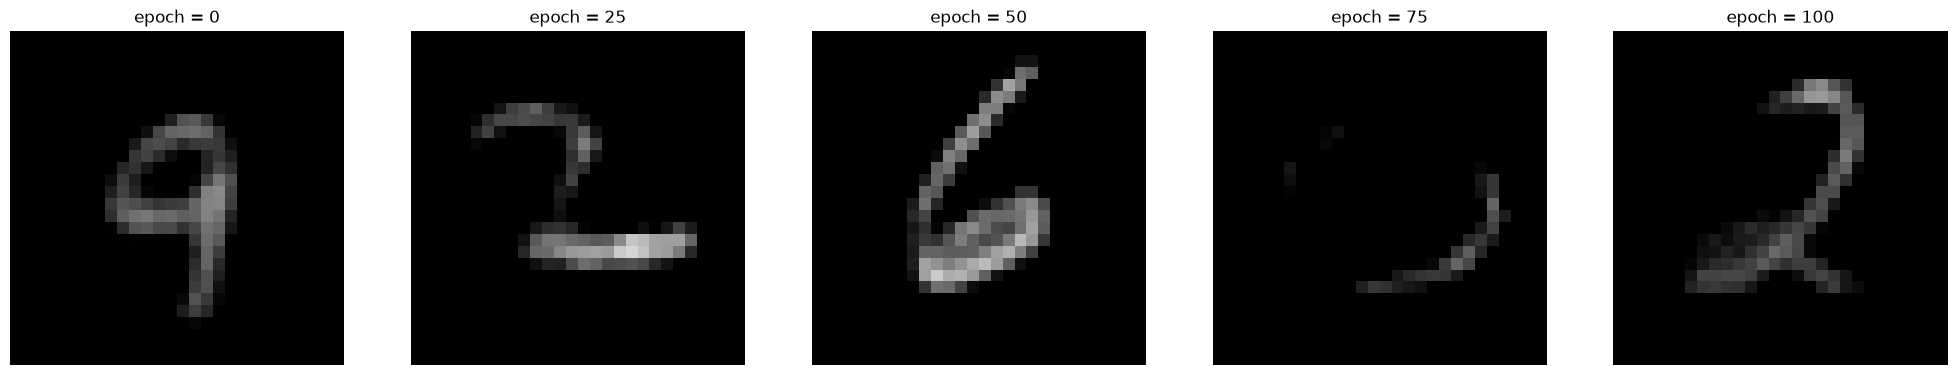

In [12]:

fig, ax = plt.subplots(1, 5, figsize=(25, 10))
ax = ax.reshape(-1)
ax[0] = show_samples(preds[0].view(-1, 1, 28, 28), nrow=2, ax=ax[0])
ax[0].set_title('epoch = 0')
ax[1] = show_samples(preds[25].view(-1, 1, 28, 28), nrow=2, ax=ax[1])
ax[1].set_title('epoch = 25')
ax[2] = show_samples(preds[50].view(-1, 1, 28, 28), nrow=2, ax=ax[2])
ax[2].set_title('epoch = 50')
ax[3] = show_samples(preds[75].view(-1, 1, 28, 28), nrow=2, ax=ax[3])
ax[3].set_title('epoch = 75')
ax[4] = show_samples(preds[-1].view(-1, 1, 28, 28), nrow=2, ax=ax[4])
ax[4].set_title('epoch = 100')

plt.show()

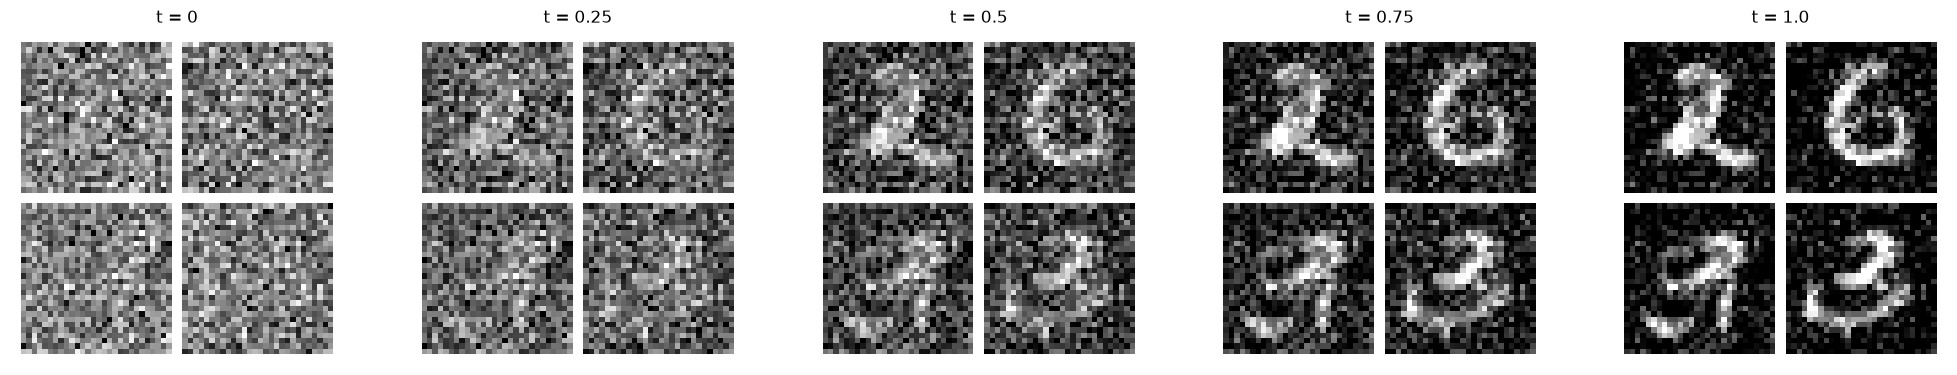

In [13]:
x = torch.randn(6, 784).to(device)*0.2 + 0.5
l = torch.randint(10, (6,)).to(device)
n_steps = 100
time_steps = torch.linspace(0, 1.0, n_steps + 1)

# Precompute the point cloud at every time step.
states = [x]
with torch.no_grad():
    for i in range(n_steps):
        x = cond_flow.step(x_t=x, t_start=time_steps[i].to(device), t_end=time_steps[i + 1].to(device), c=l)
        states.append(x)
states = [s.detach() for s in states]

fig, ax = plt.subplots(1, 5, figsize=(25, 10))
ax = ax.reshape(-1)
ax[0] = show_samples(states[0].view(-1, 1, 28, 28), nrow=2, ax=ax[0])
ax[0].set_title('t = 0')
ax[1] = show_samples(states[int(n_steps*0.25)].view(-1, 1, 28, 28), nrow=2, ax=ax[1])
ax[1].set_title('t = 0.25')
ax[2] = show_samples(states[int(n_steps*0.5)].view(-1, 1, 28, 28), nrow=2, ax=ax[2])
ax[2].set_title('t = 0.5')
ax[3] = show_samples(states[int(n_steps*0.75)].view(-1, 1, 28, 28), nrow=2, ax=ax[3])
ax[3].set_title('t = 0.75')
ax[4] = show_samples(states[-1].view(-1, 1, 28, 28), nrow=2, ax=ax[4])
ax[4].set_title('t = 1.0')

plt.show()

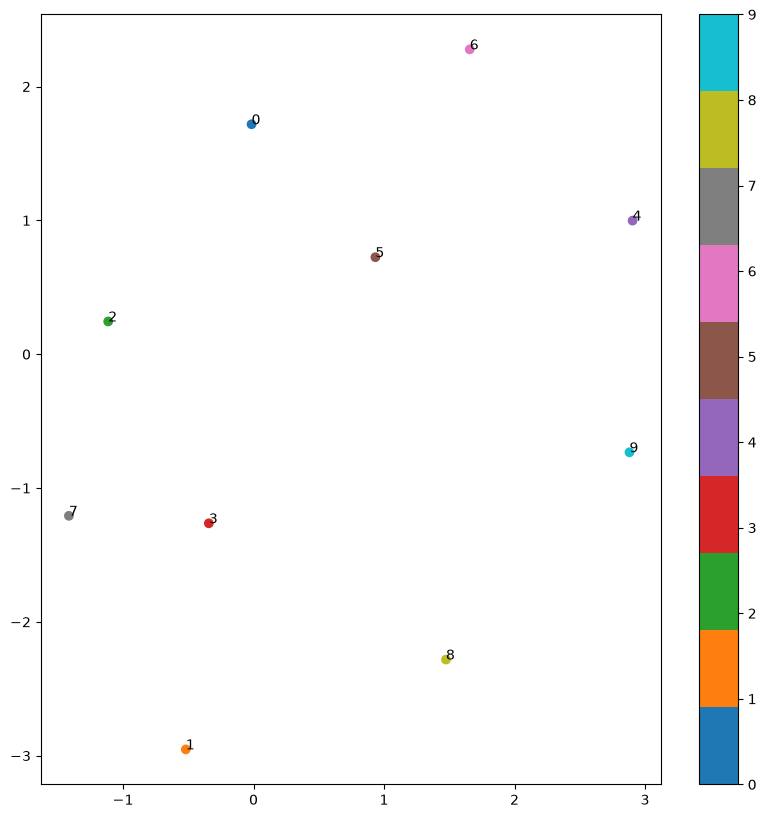

In [14]:
## Visualize embedings
emb = cond_flow.class_emb.weight.data.cpu().numpy()
fig, ax = plt.subplots(figsize=(10, 10))
scatter = ax.scatter(emb[:, 0], emb[:, 1], c=np.arange(10), cmap='tab10')
plt.colorbar(scatter)
for i in range(10):
    ax.annotate(str(i), (emb[i, 0], emb[i, 1]))
plt.show()




### Learning conditional embeddings in the image domain

In [36]:
class CondFlow(nn.Module):
    def __init__(self, dim: int = 784, h: int = 64):
        super().__init__()
        self.class_emb = nn.Embedding(10, dim)
        self.encoder = nn.Sequential(
            nn.Linear(dim+1, h),
            nn.ReLU(),
            nn.Linear(h, h),
        )
        self.decoder = nn.Sequential(
            nn.Linear(h, h),
            nn.ReLU(),
            nn.Linear(h, dim),
            # nn.Sigmoid()
        )
    
    def forward(self, t: Tensor, c: Tensor, x_t: Tensor ) -> Tensor:
        c_emb = self.class_emb(c)
        inp = torch.cat((x_t + c_emb, t), 1)
        z = self.encoder(inp)
        return self.decoder(z)
    
    def step(self, x_t: Tensor, t_start: Tensor, t_end: Tensor, c: Tensor) -> Tensor:
        t_start = t_start.view(1, 1).expand(x_t.shape[0], 1)
        dt = t_end - t_start
        return x_t + dt * self(x_t=x_t + self(x_t=x_t, t=t_start, c=c)*dt/2, t=t_start + dt/2, c=c)

In [38]:
cond_flow = CondFlow(h=256).to(device)
losses = train_cond(cond_flow, train_loader, n_epochs=100, lr=1e-3, sigma_noise=0.1, device=device)

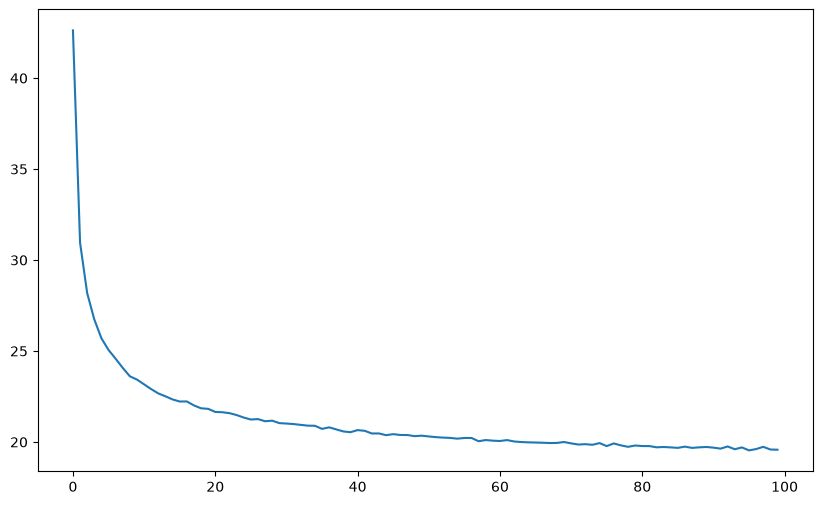

In [39]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(losses)
plt.show();

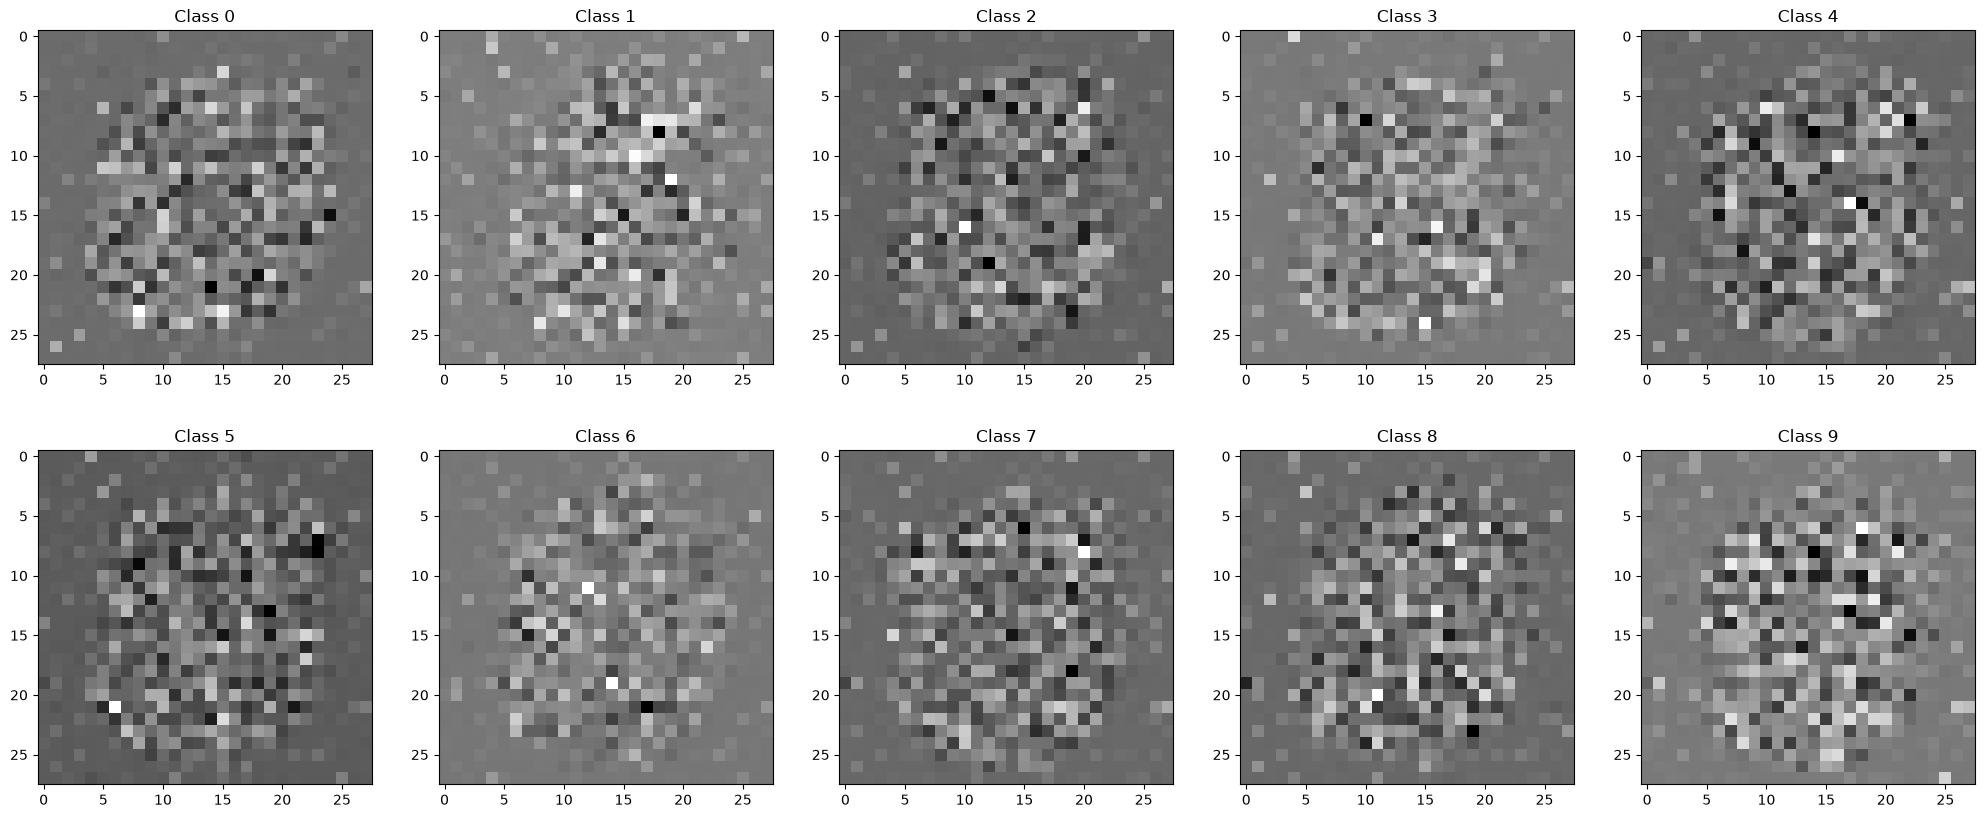

In [41]:
fig, ax = plt.subplots(2, 5, figsize=(25, 10))
ax = ax.reshape(-1)
for i in range(10):
    mu = cond_flow.class_emb(torch.tensor(i).to(device)).detach().cpu()
    mu = (mu - mu.min()) / (mu.max() - mu.min())
    ax[i].imshow(mu.view(28, 28), cmap='gray')
    ax[i].set_title(f'Class {i}')

plt.show()

## Condition on base distribution

In [15]:
class CondBaseFlow(nn.Module):
    def __init__(self, dim: int = 784, h: int = 64):
        super().__init__()
        self.mu_emb = nn.Embedding(10, dim)
        # self.log_sigma_emb = nn.Embedding(10, dim)
        self.encoder = nn.Sequential(
            nn.Linear(dim+1, h),
            nn.ReLU(),
            nn.Linear(h, h),
        )
        self.decoder = nn.Sequential(
            nn.Linear(h, h),
            nn.ReLU(),
            nn.Linear(h, dim),
            # nn.Sigmoid()
        )
    
    def forward(self, t: Tensor, x_t: Tensor ) -> Tensor:
        inp = torch.cat((x_t, t), 1)
        z = self.encoder(inp)
        return self.decoder(z)
    
    def step(self, x_t: Tensor, t_start: Tensor, t_end: Tensor) -> Tensor:
        t_start = t_start.view(1, 1).expand(x_t.shape[0], 1)
        dt = t_end - t_start
        return x_t + dt * self(x_t=x_t + self(x_t=x_t, t=t_start)*dt/2, t=t_start + dt/2)

In [16]:
N_EPOCHS = 50

cond_bflow = CondBaseFlow(h=512).to(device)
opt = torch.optim.Adam(cond_bflow.parameters(), lr=1e-3)
losses = []
preds = []
for e in range(N_EPOCHS):
    tot_loss = 0
    n = 0
    for i, (x, l) in enumerate(train_loader):
        x_1 = x.view(-1, 784).to(device)
        l = l.to(device)

        mu = cond_bflow.mu_emb(l)

        t = torch.rand(x.shape[0], 1, device=x_1.device)
        x_0 = torch.randn_like(x_1)*0.2 + mu
        dx_t = x_1 - x_0
        x_t = (1-t)*x_0 + t * x_1
        flow_pred = cond_bflow(x_t=x_t, t=t)

        loss = (flow_pred - dx_t).pow(2).sum(dim=1).mean()
        loss.backward()
        tot_loss += loss.item()
        n+=1
        opt.step()
        opt.zero_grad()

        if i % 200 == 0:
            print(f'Epoch: {e}, Iter: {i}, Loss: {loss.item():.4f}')
    preds.append(flow_pred[0].cpu().detach().numpy())
    losses.append(tot_loss/n)

Epoch: 0, Iter: 0, Loss: 915.1124
Epoch: 0, Iter: 200, Loss: 94.4672
Epoch: 0, Iter: 400, Loss: 77.5607
Epoch: 1, Iter: 0, Loss: 73.7747
Epoch: 1, Iter: 200, Loss: 67.5474
Epoch: 1, Iter: 400, Loss: 64.7479
Epoch: 2, Iter: 0, Loss: 68.8549
Epoch: 2, Iter: 200, Loss: 65.5112
Epoch: 2, Iter: 400, Loss: 58.3430
Epoch: 3, Iter: 0, Loss: 62.5424
Epoch: 3, Iter: 200, Loss: 59.7353
Epoch: 3, Iter: 400, Loss: 56.8326
Epoch: 4, Iter: 0, Loss: 59.5035
Epoch: 4, Iter: 200, Loss: 57.9137
Epoch: 4, Iter: 400, Loss: 56.6097
Epoch: 5, Iter: 0, Loss: 55.1069
Epoch: 5, Iter: 200, Loss: 54.8045
Epoch: 5, Iter: 400, Loss: 55.9594
Epoch: 6, Iter: 0, Loss: 56.3237
Epoch: 6, Iter: 200, Loss: 52.7009
Epoch: 6, Iter: 400, Loss: 54.9551
Epoch: 7, Iter: 0, Loss: 54.5335
Epoch: 7, Iter: 200, Loss: 54.0710
Epoch: 7, Iter: 400, Loss: 50.9923
Epoch: 8, Iter: 0, Loss: 54.7501
Epoch: 8, Iter: 200, Loss: 51.2274
Epoch: 8, Iter: 400, Loss: 55.8117
Epoch: 9, Iter: 0, Loss: 52.6307
Epoch: 9, Iter: 200, Loss: 52.1501
Epoc

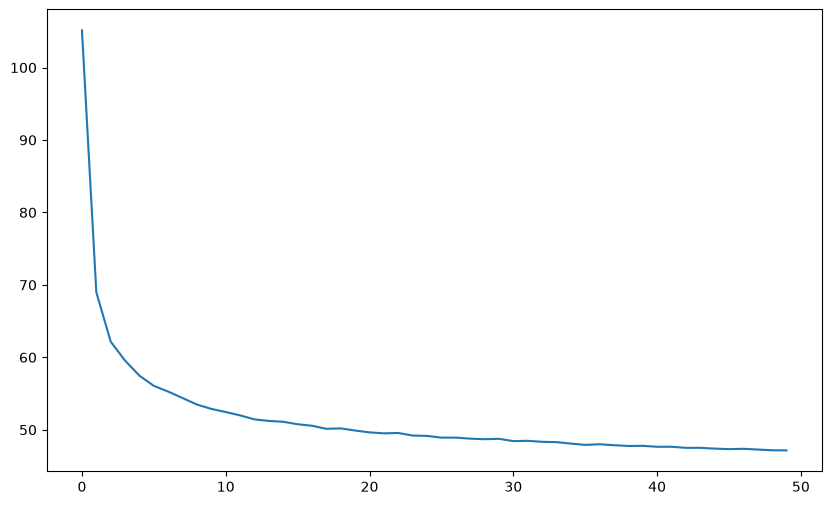

In [17]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(losses)
plt.show();

Text(0.5, 1.0, 't = 1.0')

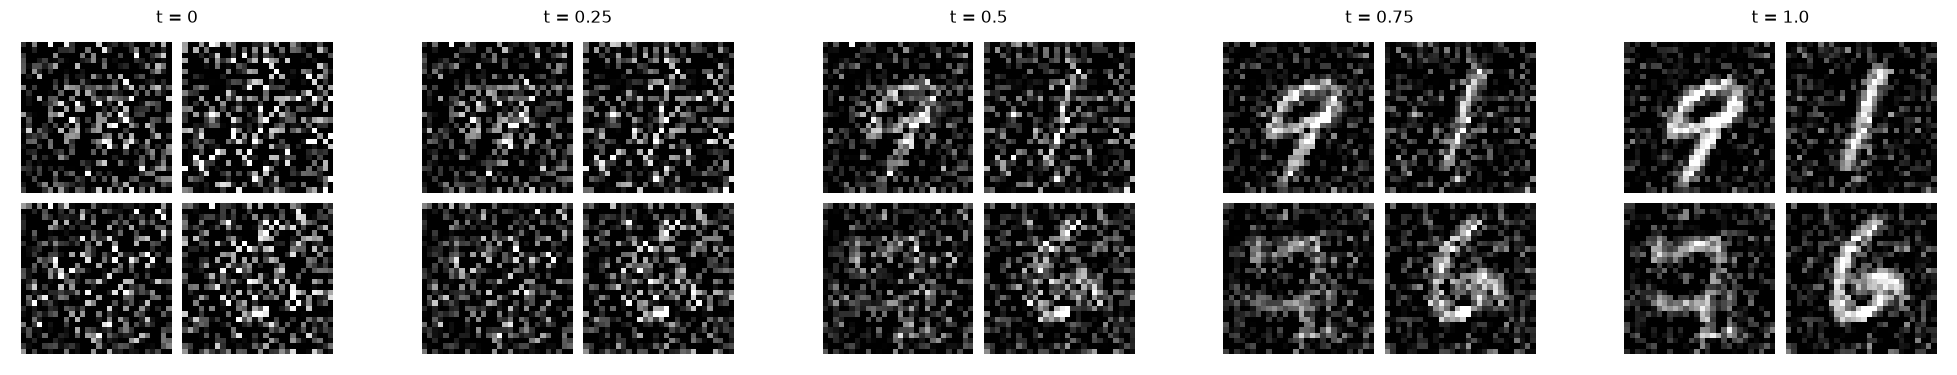

In [18]:
x = torch.randn(6, 784).to(device)
l = torch.randint(10, (6,)).to(device)
mu = cond_bflow.mu_emb(l)
x = x * 0.2 + mu
n_steps = 100
time_steps = torch.linspace(0, 1.0, n_steps + 1)

# Precompute the point cloud at every time step.
states = [x]
with torch.no_grad():
    for i in range(n_steps):
        x = cond_bflow.step(x_t=x, t_start=time_steps[i].to(device), t_end=time_steps[i + 1].to(device))
        states.append(x)
states = [s.detach() for s in states]

fig, ax = plt.subplots(1, 5, figsize=(25, 10))
ax = ax.reshape(-1)
ax[0] = show_samples(states[0].view(-1, 1, 28, 28), nrow=2, ax=ax[0])
ax[0].set_title('t = 0')
ax[1] = show_samples(states[int(n_steps*0.25)].view(-1, 1, 28, 28), nrow=2, ax=ax[1])
ax[1].set_title('t = 0.25')
ax[2] = show_samples(states[int(n_steps*0.5)].view(-1, 1, 28, 28), nrow=2, ax=ax[2])
ax[2].set_title('t = 0.5')
ax[3] = show_samples(states[int(n_steps*0.75)].view(-1, 1, 28, 28), nrow=2, ax=ax[3])
ax[3].set_title('t = 0.75')
ax[4] = show_samples(states[-1].view(-1, 1, 28, 28), nrow=2, ax=ax[4])
ax[4].set_title('t = 1.0')

In [19]:
l

tensor([9, 1, 7, 6, 9, 9], device='cuda:0')

### Optimal transport coupling


In [10]:
from scipy.optimize import linear_sum_assignment
from scipy.spatial import distance

In [26]:
def train_flow(flow, train_loader, use_OT=True, n_epochs=50, lr=1e-3, sigma_noise=0.2, device=device):
    losses = []
    opt = torch.optim.Adam(flow.parameters(), lr=lr)
    t0 = time.time()
    for e in range(n_epochs):
        current_loss = 0.0
        for i, (x, _) in enumerate(train_loader):
            x_1 = x.view(-1, 784).to(device)

            t = torch.rand(x.shape[0], 1, device=x_1.device)
            x_0 = torch.randn_like(x_1)*sigma_noise + 0.5
            if use_OT:
                cost = distance.cdist(x_0.cpu().numpy(), x_1.cpu().numpy())
                row_ind, col_ind = linear_sum_assignment(cost)
                x_0, x_1 = x_0[row_ind], x_1[col_ind]

            dx_t = x_1 - x_0
            x_t = (1-t)*x_0 + t * x_1
            flow_pred = flow(x_t, t)

            loss = (flow_pred - dx_t).pow(2).sum(dim=1).mean()
            loss.backward()
            opt.step()
            opt.zero_grad()

            # display progress with escape sequences to overwrite the previous line

            current_loss += loss.item()
        avg_loss = current_loss / len(train_loader)
        losses.append(avg_loss)
        print(f'\rEnd of epoch {e} of {n_epochs} at time {time.time() - t0:.2f}s, Loss: {avg_loss:.4f}', end='', flush=True)

    return losses

In [27]:
SIGMAS = [0.01, 0.1, 0.2, 0.5]
N_EPOCHS = 20

losses_OT = {}
flows_OT = {}
losses_nOT = {}
flows_nOT = {}
for sigma in SIGMAS:
    flows_OT[sigma] = Flow(h=256).to(device)
    losses_OT[sigma] = train_flow(flows_OT[sigma], train_loader, use_OT=True, n_epochs=N_EPOCHS, sigma_noise=sigma)

    flows_nOT[sigma] = Flow(h=256).to(device)
    losses_nOT[sigma] = train_flow(flows_nOT[sigma], train_loader, use_OT=False, n_epochs=N_EPOCHS, sigma_noise=sigma)


End of epoch 19 of 20 at time 43.90s, Loss: 207.09166

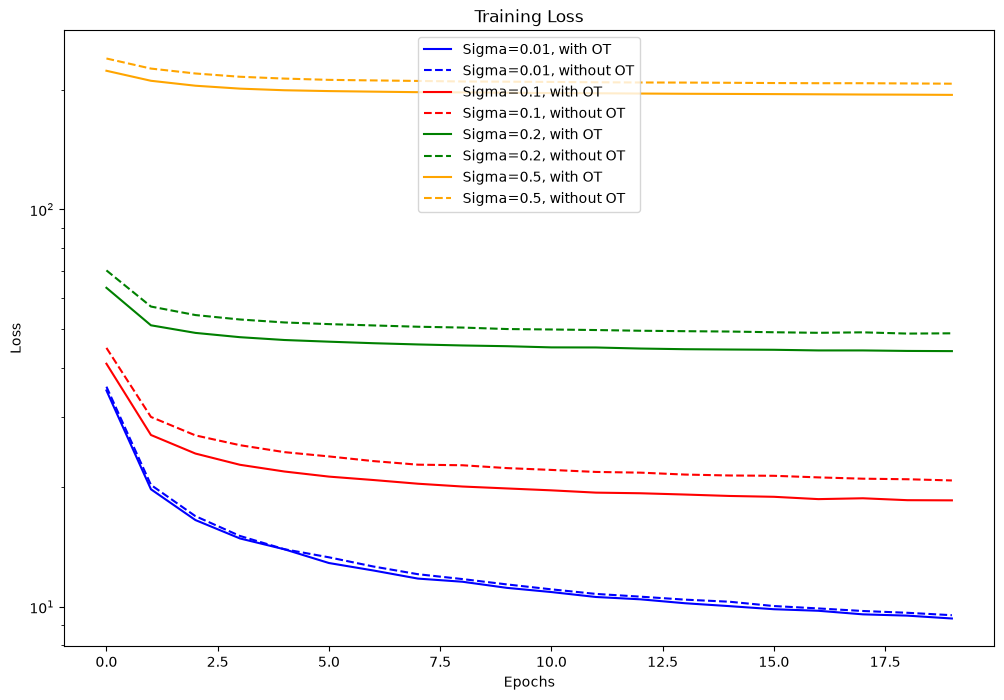

In [30]:
fig, ax = plt.subplots(figsize=(12, 8))
for sigma, c in zip(SIGMAS, ['blue', 'red', 'green', 'orange']):
    ax.plot(losses_OT[sigma], label=f'Sigma={sigma}, with OT', color=c)
    ax.plot(losses_nOT[sigma], label=f'Sigma={sigma}, without OT', color=c, linestyle='--')
ax.set_yscale('log')
ax.set_title('Training Loss')
ax.set_xlabel('Epochs')
ax.set_ylabel('Loss')
ax.legend()
plt.show()

In [12]:
N_EPOCHS = 100

flow = Flow(h=256).to(device)
opt = torch.optim.Adam(flow.parameters(), lr=1e-3)

for e in range(N_EPOCHS):
    for i, (x, _) in enumerate(train_loader):
        x_1 = x.view(-1, 784).to(device)

        t = torch.rand(x.shape[0], 1, device=x_1.device)
        x_0 = torch.randn_like(x_1)*0.2 + 0.5
        cost = distance.cdist(x_0.cpu().numpy(), x_1.cpu().numpy())
        row_ind, col_ind = linear_sum_assignment(cost)
        dx_t = x_1[col_ind] - x_0[row_ind]
        x_t = (1-t)*x_0[row_ind] + t * x_1[col_ind]
        flow_pred = flow(x_t, t)

        loss = (flow_pred - dx_t).pow(2).sum(dim=1).mean()
        loss.backward()
        opt.step()
        opt.zero_grad()

        if i % 50 == 0:
            print(f'Epoch: {e}, Iter: {i}, Loss: {loss.item():.4f}')

Epoch: 0, Iter: 0, Loss: 206.8143
Epoch: 0, Iter: 50, Loss: 76.4659
Epoch: 0, Iter: 100, Loss: 70.1754
Epoch: 0, Iter: 150, Loss: 62.5675
Epoch: 0, Iter: 200, Loss: 61.4720
Epoch: 0, Iter: 250, Loss: 61.6926
Epoch: 0, Iter: 300, Loss: 56.6534
Epoch: 0, Iter: 350, Loss: 54.9414
Epoch: 0, Iter: 400, Loss: 53.9691
Epoch: 0, Iter: 450, Loss: 54.0584
Epoch: 1, Iter: 0, Loss: 53.2293
Epoch: 1, Iter: 50, Loss: 51.0182
Epoch: 1, Iter: 100, Loss: 52.0639
Epoch: 1, Iter: 150, Loss: 51.2561
Epoch: 1, Iter: 200, Loss: 51.8837
Epoch: 1, Iter: 250, Loss: 49.6777
Epoch: 1, Iter: 300, Loss: 49.8918
Epoch: 1, Iter: 350, Loss: 49.6872
Epoch: 1, Iter: 400, Loss: 49.6460
Epoch: 1, Iter: 450, Loss: 49.0076
Epoch: 2, Iter: 0, Loss: 50.6161
Epoch: 2, Iter: 50, Loss: 49.2680
Epoch: 2, Iter: 100, Loss: 49.0263
Epoch: 2, Iter: 150, Loss: 48.7620
Epoch: 2, Iter: 200, Loss: 48.9553
Epoch: 2, Iter: 250, Loss: 49.1361
Epoch: 2, Iter: 300, Loss: 47.2237
Epoch: 2, Iter: 350, Loss: 46.7901
Epoch: 2, Iter: 400, Loss: 4

KeyboardInterrupt: 

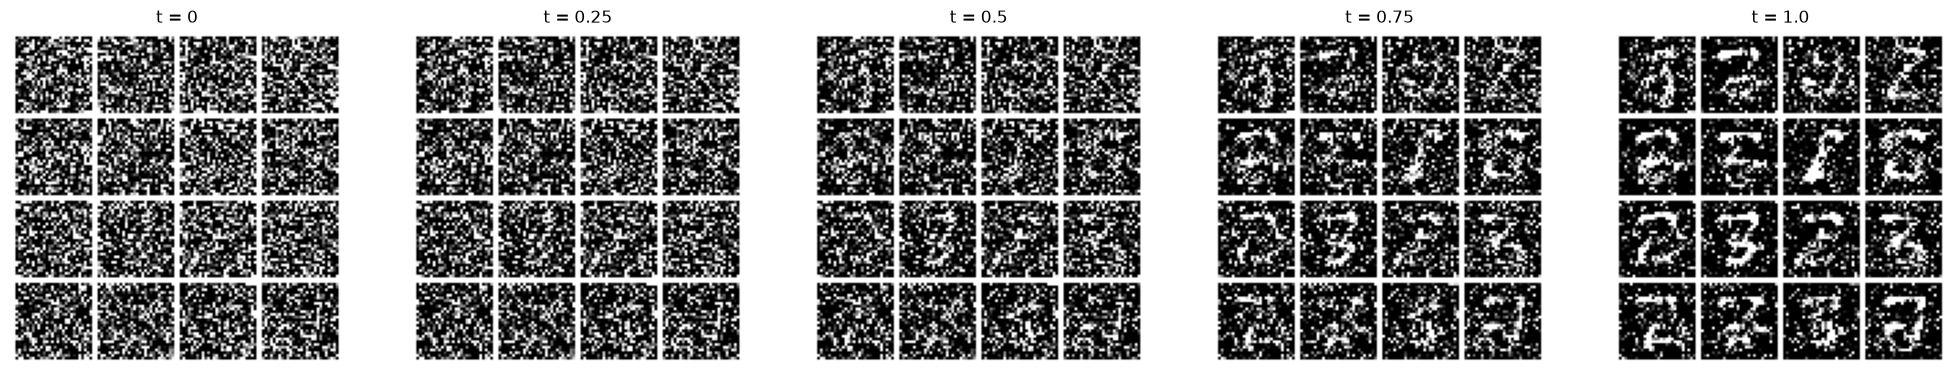

In [13]:
x = torch.randn(16, 784).to(device)
n_steps = 100
time_steps = torch.linspace(0, 1.0, n_steps + 1)

# Precompute the point cloud at every time step.
states = [x]
with torch.no_grad():
    for i in range(n_steps):
        x = flow.step(x_t=x, t_start=time_steps[i].to(device), t_end=time_steps[i + 1].to(device))
        states.append(x)
states = [s.detach() for s in states]

fig, ax = plt.subplots(1, 5, figsize=(25, 10))
ax = ax.reshape(-1)
ax[0] = show_samples(states[0].view(-1, 1, 28, 28), nrow=4, ax=ax[0])
ax[0].set_title('t = 0')
ax[1] = show_samples(states[25].view(-1, 1, 28, 28), nrow=4, ax=ax[1])
ax[1].set_title('t = 0.25')
ax[2] = show_samples(states[50].view(-1, 1, 28, 28), nrow=4, ax=ax[2])
ax[2].set_title('t = 0.5')
ax[3] = show_samples(states[75].view(-1, 1, 28, 28), nrow=4, ax=ax[3])
ax[3].set_title('t = 0.75')
ax[4] = show_samples(states[-1].view(-1, 1, 28, 28), nrow=4, ax=ax[4])
ax[4].set_title('t = 1.0')

plt.show()


### Will it identify modes?

In [16]:
mus = torch.randn(10, 784).to(device)*0.2 + 0.5

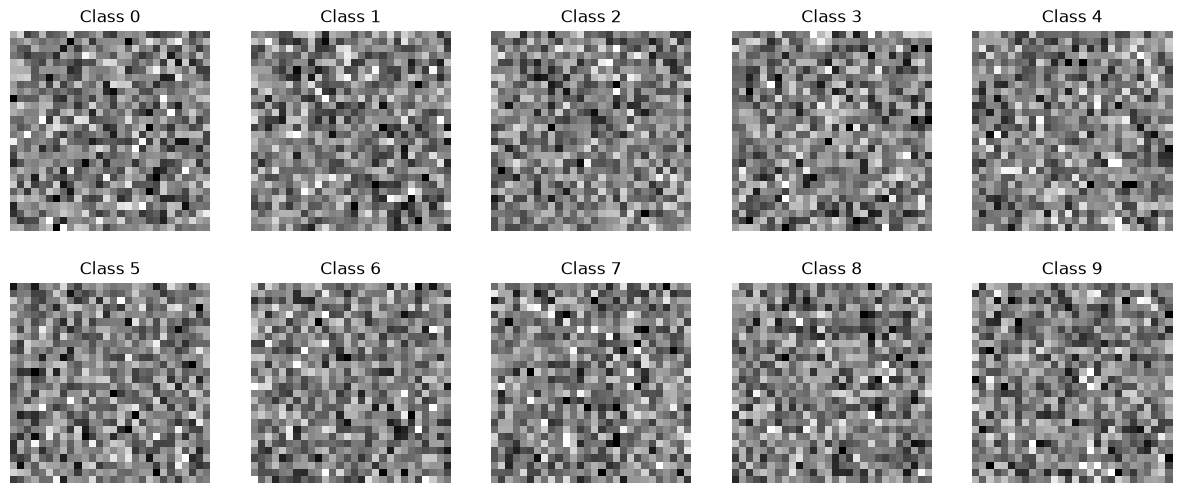

In [19]:
fig, axs = plt.subplots(2, 5, figsize=(15, 6))
for i in range(10):
    axs[i//5, i%5] = show_samples(mus[i].view(-1, 1, 28, 28), nrow=1, ax=axs[i//5, i%5])
    axs[i//5, i%5].set_title(f'Class {i}')

plt.show()

In [18]:
N_EPOCHS = 50

flow = Flow(h=256).to(device)
opt = torch.optim.Adam(flow.parameters(), lr=1e-3)

losses = []

for e in range(N_EPOCHS):
    curr_loss = 0
    for i, (x, _) in enumerate(train_loader):
        x_1 = x.view(-1, 784).to(device)

        t = torch.rand(x.shape[0], 1, device=x_1.device)

        modes = torch.randint(0, 10, (x_1.shape[0],), device=x_1.device)

        x_0 = torch.randn_like(x_1)*0.2 + mus[modes]
        cost = distance.cdist(x_0.cpu().numpy(), x_1.cpu().numpy())
        row_ind, col_ind = linear_sum_assignment(cost)
        dx_t = x_1[col_ind] - x_0[row_ind]
        x_t = (1-t)*x_0[row_ind] + t * x_1[col_ind]
        flow_pred = flow(x_t, t)

        loss = (flow_pred - dx_t).pow(2).sum(dim=1).mean()
        loss.backward()
        opt.step()
        opt.zero_grad()

        curr_loss += loss.item()

        if i % 50 == 0:
            print(f'Epoch: {e}, Iter: {i}, Loss: {loss.item():.4f}')
    losses.append(curr_loss/(i+1))

Epoch: 0, Iter: 0, Loss: 234.2689
Epoch: 0, Iter: 50, Loss: 103.2255
Epoch: 0, Iter: 100, Loss: 84.6680
Epoch: 0, Iter: 150, Loss: 71.3423
Epoch: 0, Iter: 200, Loss: 68.5627
Epoch: 0, Iter: 250, Loss: 63.5209
Epoch: 0, Iter: 300, Loss: 62.4949
Epoch: 0, Iter: 350, Loss: 59.4091
Epoch: 0, Iter: 400, Loss: 59.8157
Epoch: 0, Iter: 450, Loss: 57.2731
Epoch: 1, Iter: 0, Loss: 58.7312
Epoch: 1, Iter: 50, Loss: 56.0848
Epoch: 1, Iter: 100, Loss: 56.2921
Epoch: 1, Iter: 150, Loss: 55.4424
Epoch: 1, Iter: 200, Loss: 55.4780
Epoch: 1, Iter: 250, Loss: 54.2824
Epoch: 1, Iter: 300, Loss: 53.4556
Epoch: 1, Iter: 350, Loss: 54.2456
Epoch: 1, Iter: 400, Loss: 53.3815
Epoch: 1, Iter: 450, Loss: 54.0457
Epoch: 2, Iter: 0, Loss: 50.8588
Epoch: 2, Iter: 50, Loss: 51.7990
Epoch: 2, Iter: 100, Loss: 53.1682
Epoch: 2, Iter: 150, Loss: 52.8791
Epoch: 2, Iter: 200, Loss: 54.0530
Epoch: 2, Iter: 250, Loss: 51.5525
Epoch: 2, Iter: 300, Loss: 49.7640
Epoch: 2, Iter: 350, Loss: 51.8664
Epoch: 2, Iter: 400, Loss: 

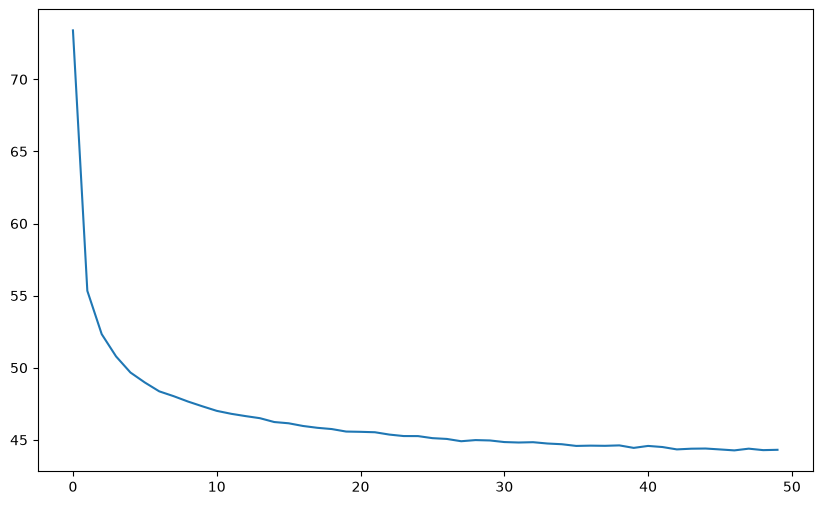

In [20]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(losses)
plt.show();

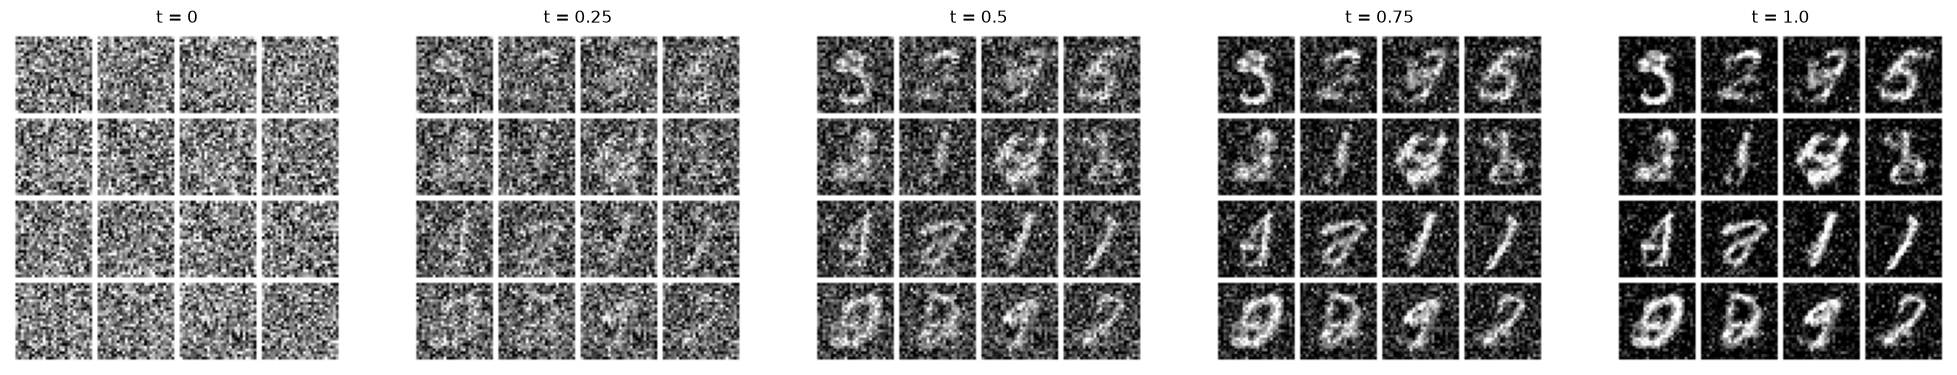

In [22]:


modes = torch.randint(0, 10, (16,), device=device)

x = torch.randn(16, 784).to(device)*0.2 + mus[modes]
n_steps = 100
time_steps = torch.linspace(0, 1.0, n_steps + 1)

# Precompute the point cloud at every time step.
states = [x]
with torch.no_grad():
    for i in range(n_steps):
        x = flow.step(x_t=x, t_start=time_steps[i].to(device), t_end=time_steps[i + 1].to(device))
        states.append(x)
states = [s.detach() for s in states]

fig, ax = plt.subplots(1, 5, figsize=(25, 10))
ax = ax.reshape(-1)
ax[0] = show_samples(states[0].view(-1, 1, 28, 28), nrow=4, ax=ax[0])
ax[0].set_title('t = 0')
ax[1] = show_samples(states[25].view(-1, 1, 28, 28), nrow=4, ax=ax[1])
ax[1].set_title('t = 0.25')
ax[2] = show_samples(states[50].view(-1, 1, 28, 28), nrow=4, ax=ax[2])
ax[2].set_title('t = 0.5')
ax[3] = show_samples(states[75].view(-1, 1, 28, 28), nrow=4, ax=ax[3])
ax[3].set_title('t = 0.75')
ax[4] = show_samples(states[-1].view(-1, 1, 28, 28), nrow=4, ax=ax[4])
ax[4].set_title('t = 1.0')

plt.show()

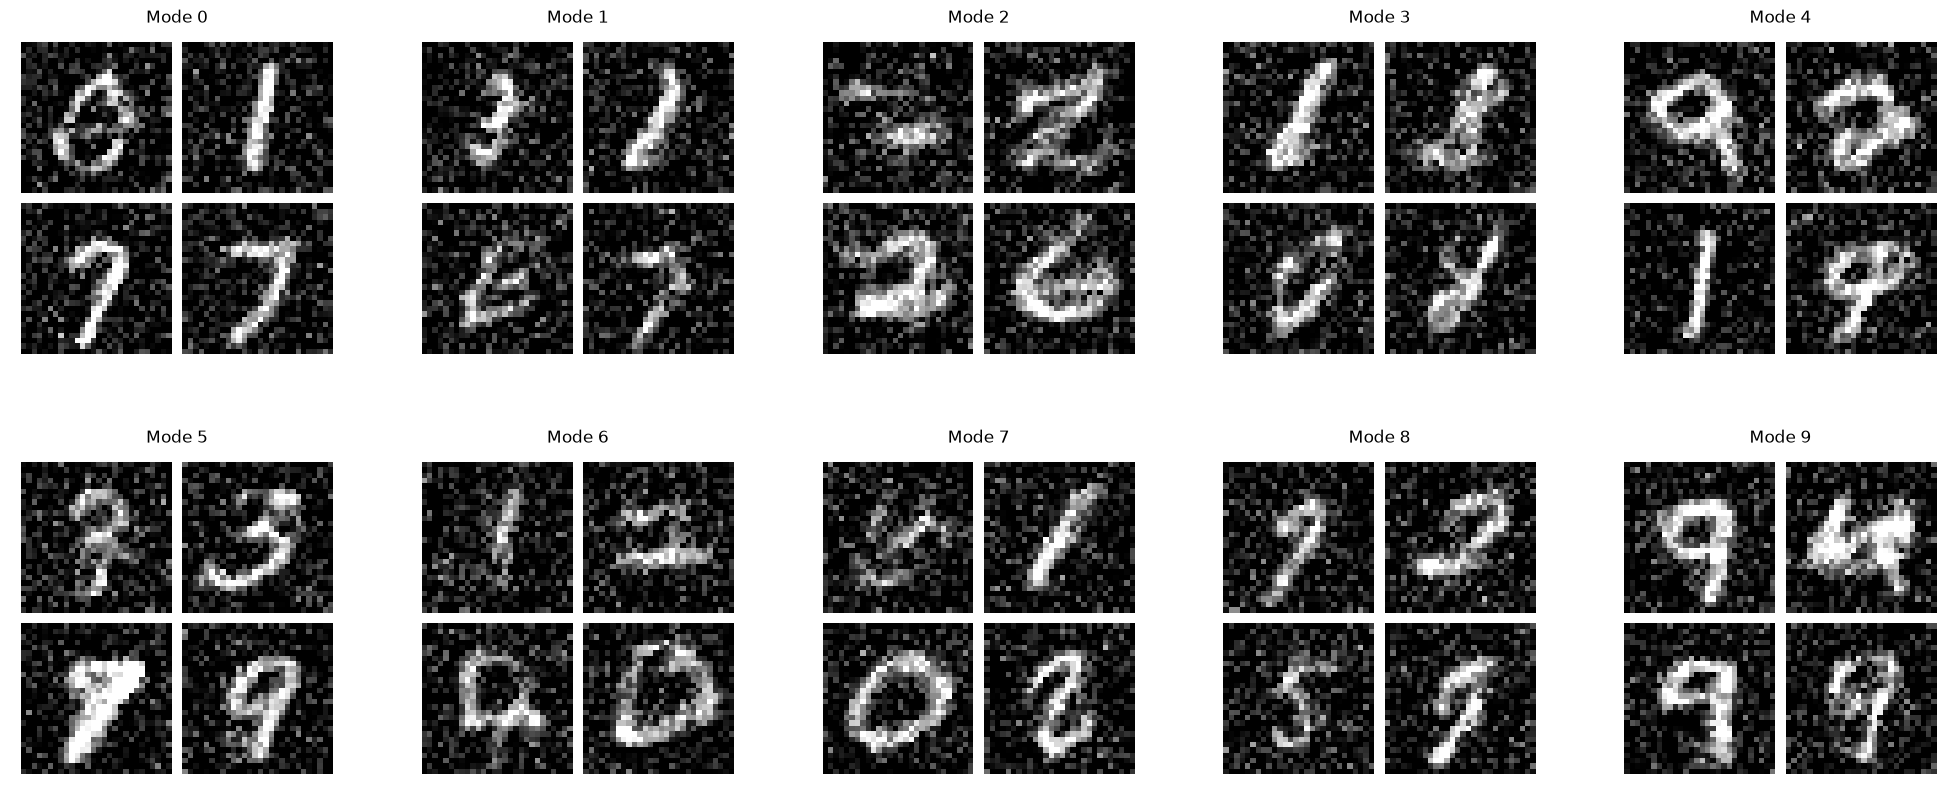

In [24]:
fig, ax = plt.subplots(2, 5, figsize=(25, 10))
ax = ax.reshape(-1)
for i in range(10):
    with torch.no_grad():
        x = torch.randn(4, 784).to(device)*0.2 + mus[i]
        for j in range(n_steps):
            x = flow.step(x_t=x, t_start=time_steps[j].to(device), t_end=time_steps[j + 1].to(device))
        ax[i] = show_samples(x.view(-1, 1, 28, 28), nrow=2, ax=ax[i])
        ax[i].set_title(f'Mode {i}')
plt.show()
        